# 三层神经网络：三特征输入与三目标输出

本示例使用自定义的 10,000 个样本。每个样本包含 `x1`、`x2`、`x3` 三个特征，并按照三者之和生成 `y1`、`y2`、`y3` 三个 one-hot 目标。

- `y1 = 1`：`x1 + x2 + x3 < 1`
- `y2 = 1`：`1 <= x1 + x2 + x3 < 2`
- `y3 = 1`：`x1 + x2 + x3 >= 2`

网络结构为：输入层 3 个神经元 → 隐藏层 16 个神经元 → 输出层 3 个神经元。

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

%matplotlib inline

# 保证每次运行得到相同的随机数据与初始化参数
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
print(f"使用设备：{device}")

使用设备：cpu


In [2]:
# 可修改样本数，这里按要求设置为 10,000
N_SAMPLES = 10_000

x1 = torch.rand(N_SAMPLES, 1)
x2 = torch.rand(N_SAMPLES, 1)
x3 = torch.rand(N_SAMPLES, 1)

# 将三个特征拼成形状为 [样本数, 3] 的输入矩阵
X = torch.cat([x1, x2, x3], dim=1)
print(f"X.shape = {X.shape}")

X.shape = torch.Size([10000, 3])


In [3]:
feature_sum = x1 + x2 + x3

y1 = (feature_sum < 1).float()
y2 = ((feature_sum >= 1) & (feature_sum < 2)).float()
y3 = (feature_sum >= 2).float()

# 将三个目标拼成形状为 [样本数, 3] 的 one-hot 目标矩阵
Y = torch.cat([y1, y2, y3], dim=1)

print(f"Y.shape = {Y.shape}")
print(f"类别样本数：y1={int(y1.sum())}, y2={int(y2.sum())}, y3={int(y3.sum())}")

Y.shape = torch.Size([10000, 3])
类别样本数：y1=1654, y2=6672, y3=1674


## 划分数据集并建立三层网络

三个目标互斥，因此使用 `CrossEntropyLoss`。训练时分别按类别抽取 80% 的样本组成训练集，剩余 20% 作为验证集。

In [4]:
labels = Y.argmax(dim=1)
split_generator = torch.Generator().manual_seed(SEED)
train_indices = []
val_indices = []

# 按类别分层划分，避免验证集中缺少某一类别
for class_id in torch.unique(labels):
    class_indices = torch.where(labels == class_id)[0]
    class_indices = class_indices[torch.randperm(len(class_indices), generator=split_generator)]
    split_point = int(0.8 * len(class_indices))
    train_indices.append(class_indices[:split_point])
    val_indices.append(class_indices[split_point:])

train_indices = torch.cat(train_indices)
val_indices = torch.cat(val_indices)

batch_size = 128
train_loader = DataLoader(
    TensorDataset(X[train_indices], labels[train_indices]),
    batch_size=batch_size,
    shuffle=True,
)
val_loader = DataLoader(
    TensorDataset(X[val_indices], labels[val_indices]),
    batch_size=batch_size,
    shuffle=False,
)

# 输入层(3) -> 隐藏层(16) -> 输出层(3)
model = nn.Sequential(
    nn.Linear(3, 16),
    nn.ReLU(),
    nn.Linear(16, 3),
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

print(f"训练集：{len(train_indices)} 个样本，验证集：{len(val_indices)} 个样本")
print(model)

训练集：7999 个样本，验证集：2001 个样本
Sequential(
  (0): Linear(in_features=3, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=3, bias=True)
)


In [5]:
def evaluate(model, data_loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for features, targets in data_loader:
            features = features.to(device)
            targets = targets.to(device)
            logits = model(features)
            total_loss += criterion(logits, targets).item() * len(targets)
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            total_samples += len(targets)

    return total_loss / total_samples, total_correct / total_samples


EPOCHS = 100
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    correct = 0
    seen_samples = 0

    for features, targets in train_loader:
        features = features.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        logits = model(features)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(targets)
        correct += (logits.argmax(dim=1) == targets).sum().item()
        seen_samples += len(targets)

    train_losses.append(running_loss / seen_samples)
    train_accuracies.append(correct / seen_samples)
    val_loss, val_accuracy = evaluate(model, val_loader)
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:3d}/{EPOCHS} | "
            f"训练损失 {train_losses[-1]:.4f} | 训练准确率 {train_accuracies[-1]:.4f} | "
            f"验证损失 {val_losses[-1]:.4f} | 验证准确率 {val_accuracies[-1]:.4f}"
        )

Epoch   1/100 | 训练损失 0.8071 | 训练准确率 0.6637 | 验证损失 0.6320 | 验证准确率 0.6737


Epoch  10/100 | 训练损失 0.0817 | 训练准确率 0.9867 | 验证损失 0.0767 | 验证准确率 0.9880


Epoch  20/100 | 训练损失 0.0519 | 训练准确率 0.9905 | 验证损失 0.0473 | 验证准确率 0.9970


Epoch  30/100 | 训练损失 0.0412 | 训练准确率 0.9906 | 验证损失 0.0376 | 验证准确率 0.9935


Epoch  40/100 | 训练损失 0.0345 | 训练准确率 0.9925 | 验证损失 0.0308 | 验证准确率 0.9960


Epoch  50/100 | 训练损失 0.0298 | 训练准确率 0.9931 | 验证损失 0.0277 | 验证准确率 0.9935


Epoch  60/100 | 训练损失 0.0275 | 训练准确率 0.9924 | 验证损失 0.0244 | 验证准确率 0.9970


Epoch  70/100 | 训练损失 0.0238 | 训练准确率 0.9929 | 验证损失 0.0232 | 验证准确率 0.9915


Epoch  80/100 | 训练损失 0.0211 | 训练准确率 0.9951 | 验证损失 0.0192 | 验证准确率 0.9995


Epoch  90/100 | 训练损失 0.0200 | 训练准确率 0.9950 | 验证损失 0.0187 | 验证准确率 0.9930


Epoch 100/100 | 训练损失 0.0193 | 训练准确率 0.9941 | 验证损失 0.0199 | 验证准确率 0.9925


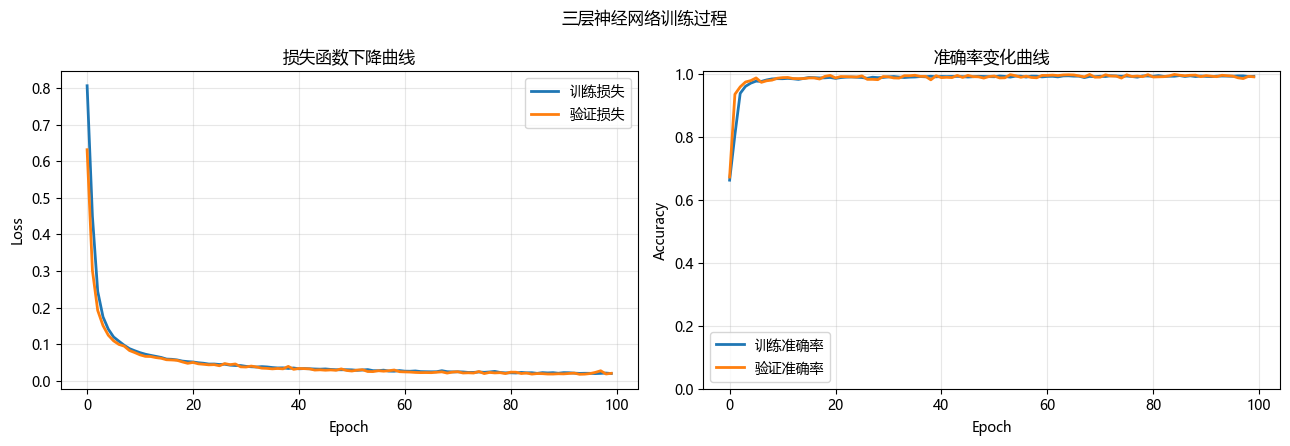

最终验证损失：0.0199
最终验证准确率：99.25%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(train_losses, label="训练损失", linewidth=2)
axes[0].plot(val_losses, label="验证损失", linewidth=2)
axes[0].set_title("损失函数下降曲线")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(train_accuracies, label="训练准确率", linewidth=2)
axes[1].plot(val_accuracies, label="验证准确率", linewidth=2)
axes[1].set_title("准确率变化曲线")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.01)
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.suptitle("三层神经网络训练过程")
plt.tight_layout()
plt.show()

final_loss, final_accuracy = evaluate(model, val_loader)
print(f"最终验证损失：{final_loss:.4f}")
print(f"最终验证准确率：{final_accuracy:.2%}")